# Excel statistical bar chart

This notebook uses `bar_chart.py` in the same folder to read an Excel workbook, calculate mean/SD, perform one-way ANOVA and Tukey HSD, and create a 600-dpi PNG bar chart.

Expected Excel layout (first worksheet):

- first column: sample names;
- first row: replicate names such as `Replicate 1`, `Replicate 2`, and `Replicate 3`;
- remaining cells: replicate measurements.

Three demo workbooks are included: `sample-1-antioxidant.xlsx`, `sample-2-antioxidant.xlsx`, and `sample-3-antioxidant.xlsx`. Set `filename` to `None` if you want to be asked for the Excel filename.

In [4]:
# Run this only if the required packages are not installed.
# %pip install -r ../requirements.txt

In [5]:
from pathlib import Path
import sys

# The notebook and bar_chart.py should be in the same folder.
NOTEBOOK_DIR = Path.cwd()
SCRIPT_PATH = NOTEBOOK_DIR / "bar_chart.py"
if not SCRIPT_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {SCRIPT_PATH}. Open this notebook from the bar-chart-demo folder."
    )

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from bar_chart import main


One-way ANOVA: F = 107.408, p = 3.01e-12

Group summary (bars show mean ± SD):
  Peptide 1: n = 3, mean = 68.433, SD = 0.404, letter = bc
  Peptide 2: n = 3, mean = 69.600, SD = 0.600, letter = bc
  Peptide 3: n = 3, mean = 49.200, SD = 0.917, letter = f
  Peptide 4: n = 3, mean = 59.967, SD = 0.808, letter = d
  Peptide 5: n = 3, mean = 81.100, SD = 2.623, letter = a
  Peptide 6: n = 3, mean = 54.933, SD = 1.955, letter = e
  Peptide 7: n = 3, mean = 72.867, SD = 2.108, letter = b
  Peptide 8: n = 3, mean = 66.833, SD = 2.495, letter = c

Tukey HSD (groups sharing a letter are not significantly different, alpha = 0.05):
  Peptide 1 vs Peptide 2: p_adj = 0.988 (not significant)
  Peptide 1 vs Peptide 3: p_adj = 6.388e-09 (significant)
  Peptide 1 vs Peptide 4: p_adj = 0.0003432 (significant)
  Peptide 1 vs Peptide 5: p_adj = 2.37e-06 (significant)
  Peptide 1 vs Peptide 6: p_adj = 9.996e-07 (significant)
  Peptide 1 vs Peptide 7: p_adj = 0.0847 (not significant)
  Peptide 1 vs Peptide 

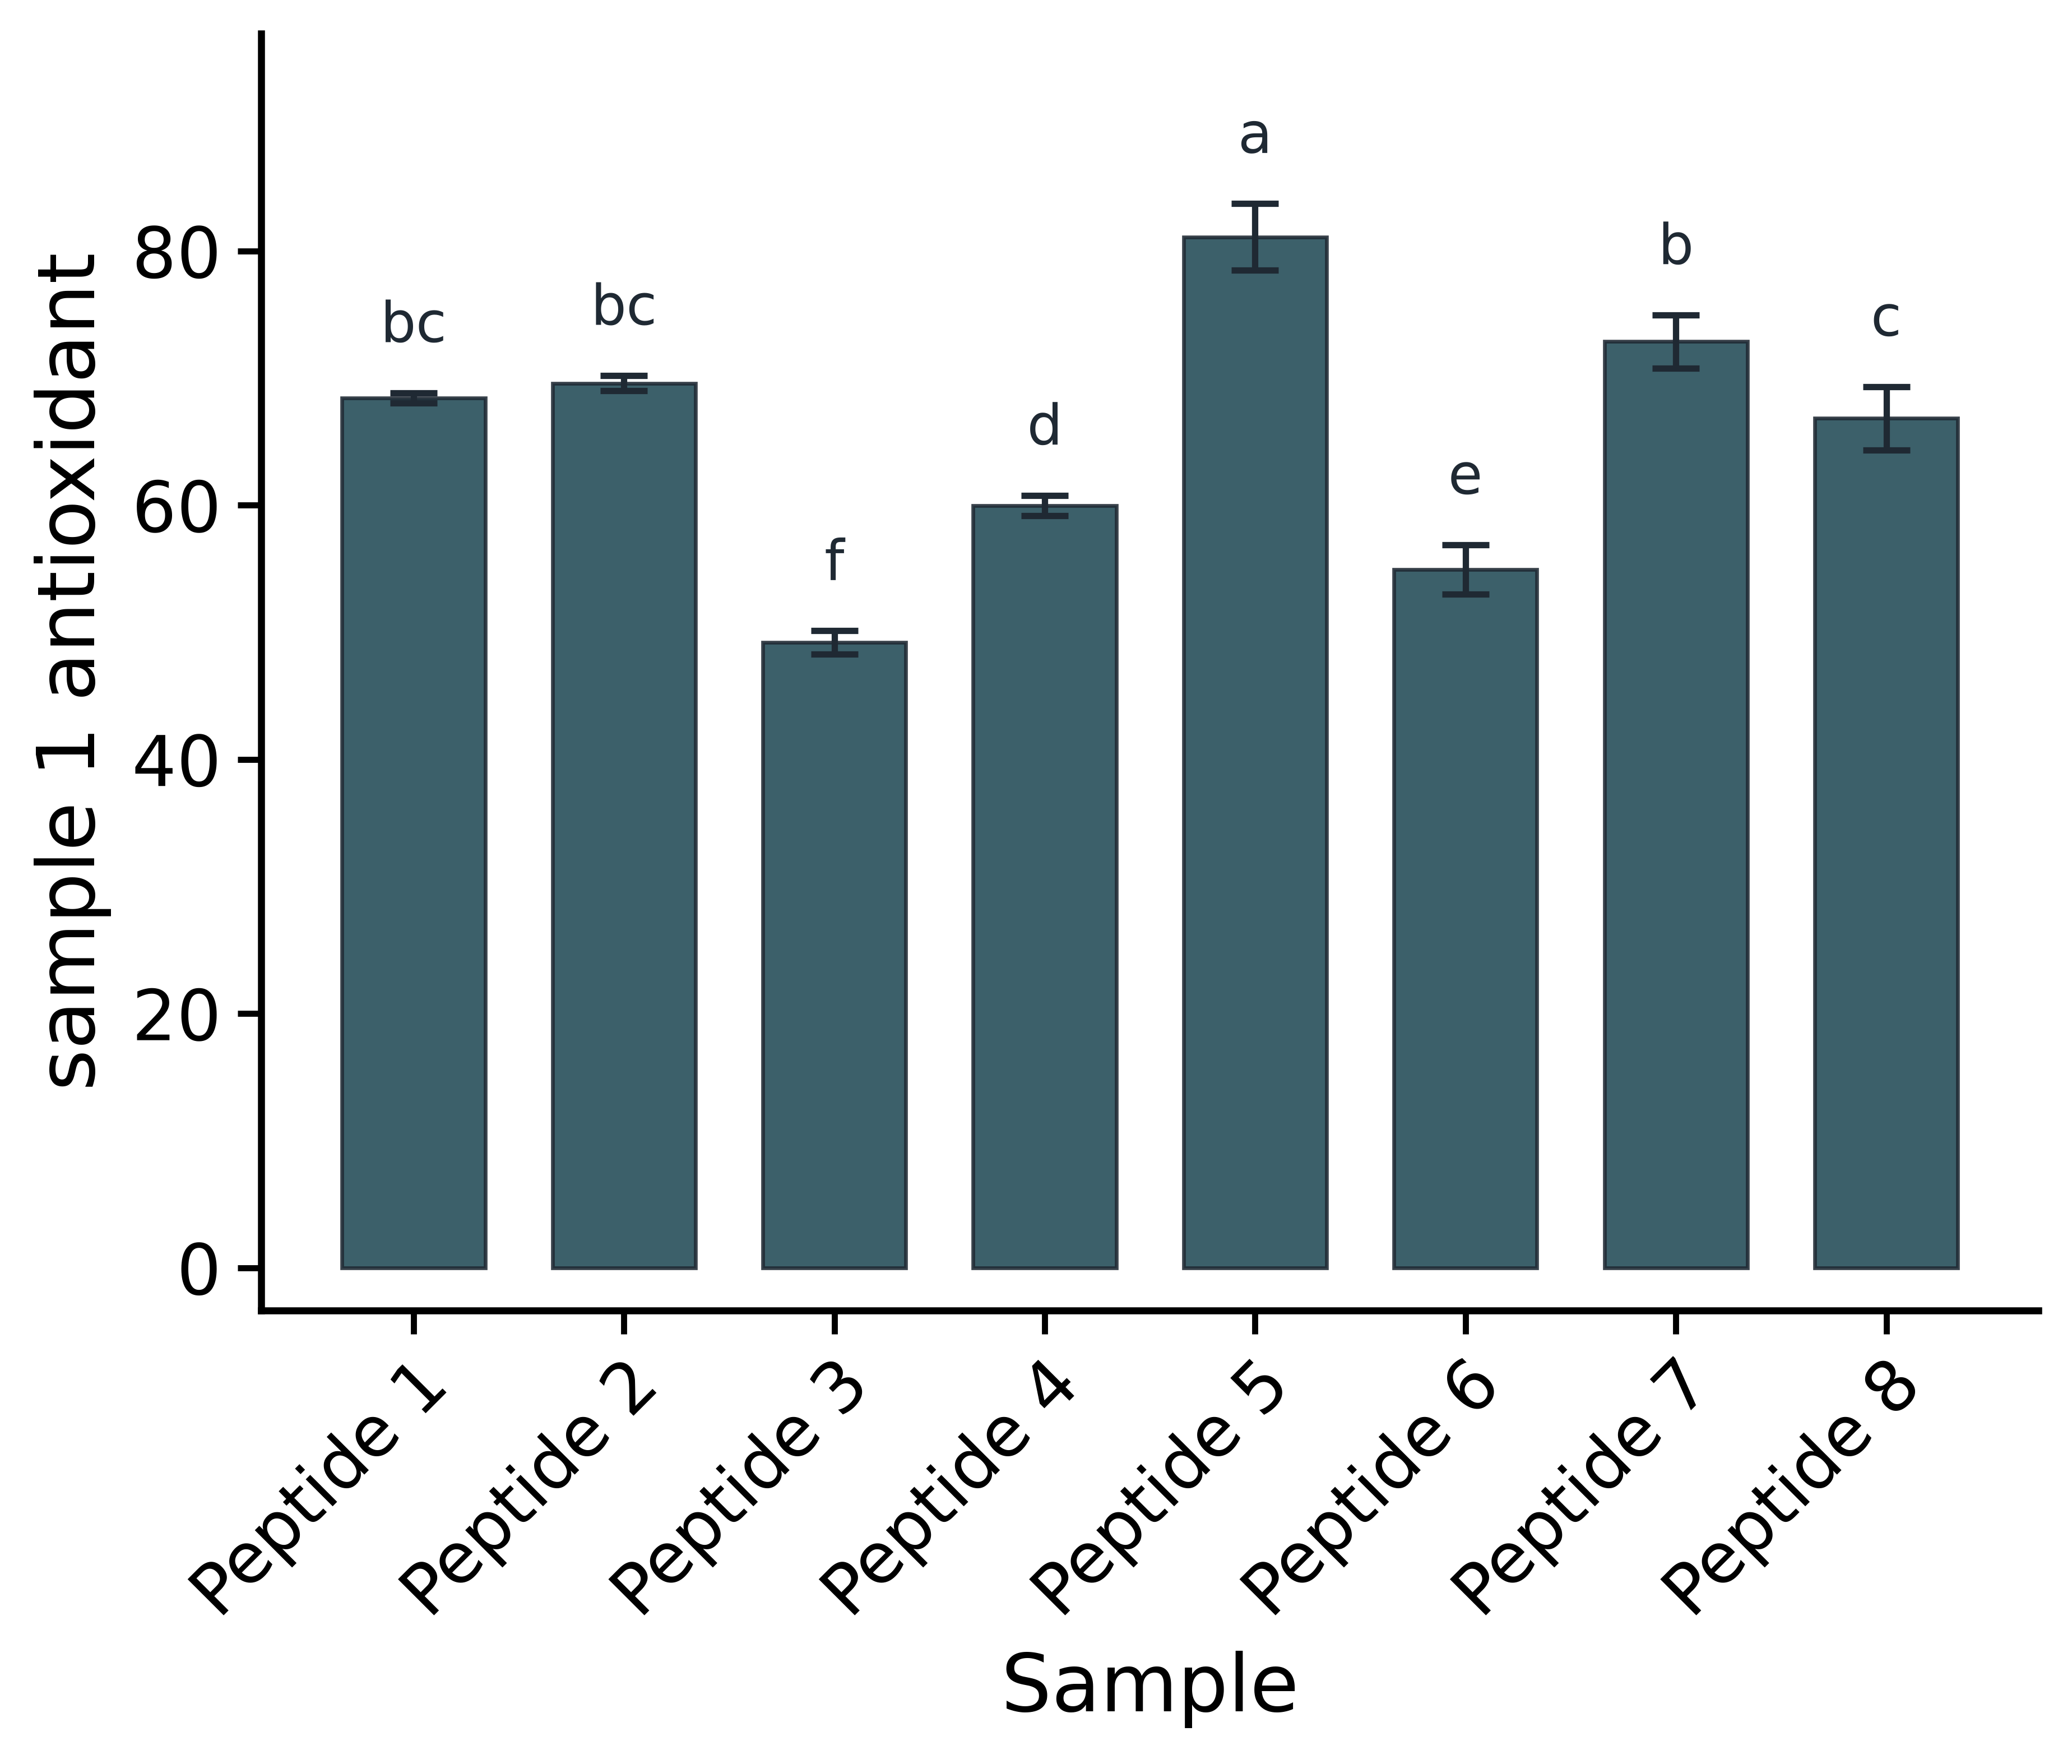

In [7]:
from IPython.display import Image, display

# Set to None to be asked for the filename.
filename = "sample-1-antioxidant.xlsx"

x_label = None                # None asks for the x-axis title before plotting
y_label = None  # None asks for the y-axis title before plotting

output_path = None  # None creates <Excel name>_barplot.png

status = main(filename, output_path, x_label, y_label)
if status == 0:
    png_path = Path(output_path) if output_path else Path(filename).with_name(f"{Path(filename).stem}_barplot.png")
    display(Image(filename=str(png_path), width=700))

## Reading the output

- Bars show the mean; error bars show the sample standard deviation (SD).
- The printed one-way ANOVA tests whether any group mean differs.
- Letters come from Tukey HSD (alpha = 0.05): two samples that **share a letter are not significantly different**; samples with no letter in common are. Letter `a` marks the highest mean, and a sample can carry more than one letter (for example `ab`).

The PNG is written beside the Excel workbook as `<workbook>_barplot.png`.